In [1]:
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# import equivariant steerable cnn
import escnn.gspaces
import escnn.nn

import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm import tqdm
# Checking if you have a GPU and CUDA set up -- if not, training will take longer by running on the CPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# device = 'cpu'
# Set the plotting style
#plt.style.use('seaborn-poster')

I keep the following snippets for loading the data in the binary classification task. But it perhaps won't apply to the data load in a SBI work. So just take it as some references.

### Load training data with a single channel

In [4]:
"""Load snapshots following a spatial random distribution"""
def load_srf(num_snaps, size, srf_data):
    snaps = torch.zeros(num_snaps, 1, size, size, dtype=torch.float32)
    data = torch.tensor(srf_data, dtype=torch.float32)
    # Set the channel to random gaussian distribution
    snaps[:, 0, :, :] = data
    # Split into a train and val set
    num_train = int(0.9 * num_snaps)
    return snaps[:num_train], snaps[num_train:]

"""Shuffle the 2d SRF into a random distribution"""
def shuffle(num_snaps, size, srf_data):
    snaps = np.zeros((num_snaps, size, size))
    for i in range(num_snaps):
        for j in range(size):
            for k in range(size):
                p = np.random.randint(0,size)
                q = np.random.randint(0,size)
                tmp = srf_data[i,j,k]
                snaps[i,j,k] = srf_data[i,p,q]
                snaps[i,p,q] = tmp
    return snaps

In [5]:
train_gaussian, val_gaussian = load_srf(5000, 200, grf_example)
train_log, val_log = load_srf(5000, 200, log_example)

### Load training data with multiple channels

In [4]:
def load_multi_channel_data(num_snaps, srf_data):
    snaps = torch.tensor(srf_data, dtype=torch.float32)
    # Split into a train and val set
    num_train = int(0.9 * num_snaps)
    return snaps[:num_train], snaps[num_train:]

In [5]:
train_w0_p, val_w0_p = load_multi_channel_data(5800, kappa_w0_p)
train_w0_m, val_w0_m = load_multi_channel_data(5800, kappa_w0_m)

In [6]:
"""Assembles tensors of snapshots into torch.DataLoaders to use during training"""
def make_datasets(train_A, train_B, val_A, val_B, batch_size=256):
    train_tensors = torch.cat([train_A, train_B])
    val_tensors = torch.cat([val_A, val_B])
    # Class A is labeled with a 0, class B is labeled with a 1
    train_labels = torch.cat([
        torch.zeros(len(train_A), dtype=torch.int64),
        torch.ones(len(train_B), dtype=torch.int64)
    ])
    val_labels = torch.cat([
        torch.zeros(len(val_A), dtype=torch.int64),
        torch.ones(len(val_B), dtype=torch.int64)
    ])
    
    train_dataset = torch.utils.data.TensorDataset(train_tensors, train_labels)
    val_dataset = torch.utils.data.TensorDataset(val_tensors, val_labels)
    
    pin_memory = True if torch.cuda.is_available() else False
    train_loader = torch.utils.data.DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, pin_memory=pin_memory
    )
    val_loader = torch.utils.data.DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory
    )
    return train_loader, val_loader

## CCNN Architecture

Below, we'll define the "simplest" CCNN architecture. 

The CCNN is a variation of the CNN, which slightly tweaks the nonlinear operation step to extract various orders of correlators out of a convolution. One way to understand these operations is as "nonlinear convolutions" which couple different numbers of pixels, defined by the operations:

$$ C_\alpha^{(1)}(\vec{x}) = \sum_{\vec{a}_1, k_1} f_{\alpha, k_1}(\vec{a}_1) S_{k_1}(\vec{x} + \vec{a}_1)$$
$$ C_\alpha^{(2)}(\vec{x}) = \sum_{(\vec{a}_1, k_1) \ne (\vec{a}_2, k_2)} f_{\alpha, k_1}(\vec{a}_1) f_{\alpha, k_2}(\vec{a}_2) S_{k_1}(\vec{x} + \vec{a}_1) S_{k_2}(\vec{x} + \vec{a}_2)$$

$$ \vdots $$

$$ C_\alpha^{(N)}(\vec{x}) = \sum_{(\vec{a}_1, k_1) \ne \dots \ne (\vec{a}_N, k_N)} \prod_{j=1}^N f_{\alpha, k_j}(\vec{a}_j) S_{k_j}(\vec{x} + \vec{a}_j)$$

Note that $C^{(1)}$ is the standard convolution as explained in the previous section. Each higher $C^{(n)}$, in expectation, measures a weighted sum of $n$-point correlators, where the weight on each correlator is equal to the product of the filter weights which make up that correlator's pattern.

Note that each of the sums are restricted such that terms where the same index pair $(\vec{a}_j, k_j)$ is not selected twice. This is to make interpretation easier down the line, as this way when interpreting what $C^{(n)}$ measures, one only needs to pick out the $n$-pixel patterns from the convolutional filter. Without this restriction, since $S$ only takes on values $\{0, 1\}$, it would be necessary to inspect all patterns in the filter with $\le n$ pixels, which would be a hassle!

However, this restriction also makes the sums difficult to compute naively. Luckily, one can show a nice recursive formula:

$$ C_\alpha^{(n)}(\vec{x}) = \frac{1}{n}\sum_{l=1}^n (-1)^{l-1} \left(\sum_{\vec{a}, k} f_{\alpha, k}(\vec{a})^l S_k(\vec{x} + \vec{a})^l \right) C_\alpha^{(n-l)}(\vec{x}) $$

Where all powers shown are done pixelwise. Using this, we can compute "correlator maps" up to $C^{(N)}$ in time $\mathcal{O}(N^2)$. This equation provides an alternate way to understand the nonlinear operation, as a modification of the function $\sigma$ to be a set of *polynomials* where the coefficients are carefully chosen to cancel out lower-order correlators.

Following this, there are just a few more components to the CCNN, as seen in the figure below, and explained afterwards. (**NOTE**: The figure below is working with 3-channel snapshots, with an additional channel containing information about the locations of holes in doped system. The model we will be building will work with 2-channel snapshots (learning 2-channel filters), since all of our test systems are "half-filled".)

![CCNN Architecture](arch.png)

If we know ahead of time that the pixel/site statistics are translation-invariant in our image, then we may as well take spatial averages of our correlator maps to produce:

$$c_\alpha^{(n)} = \frac{1}{N_{\text{sites}}} \sum_{\vec{x}} C_\alpha^{(n)}(\vec{x})$$

We'd then like to use these average correlations to distinguish the snapshots. Practically speaking, it is helpful to normalize each of these to zero mean and unit variance before using them in a classifier. Since the weights are constantly updating, this is difficult to do, but can be achieved on the batch scale using a [Batch Normalization](https://arxiv.org/abs/1502.03167v3) layer. (These are typically used as a "trick" in deep networks to speed up training, but here is important because the scales of each $c^{(n)}$ are so different, which isn't good for classification. It will also be important later in the interpretation stage.). 

What this layer does is simply normalize the features created from each *batch* of examples to have zero mean and unit variance within the batch.

Following this, we just use these features as inputs to a logistic classifier. If you are familiar with neural networks, this is really just a fully connected layer, followed by the `softmax` operation. We will label the learned weights coupling each $c_\alpha^{(n)}$ to the output as $\beta_\alpha^{(n)}$, and the final output of the neural network is:

$$\hat{y} = \frac{1}{1+ e^{-\vec{\beta}\cdot\vec{c} + \epsilon}}$$
where $\epsilon$ is a trainable bias parameter.

With all this in mind, lets construct a CCNN!

In [2]:
bandlimit = 6
gspace = escnn.gspaces.rot2dOnR2(N=-1, maximum_frequency=bandlimit)

In [3]:
""" Implements the non-linear convolution operation using the recursive formula."""
class NonlinearConv(nn.Module):
    def __init__(self, in_channels, num_filts, filter_size, order):
        super().__init__()
        self.order = order
        self.in_channels = in_channels
        self.num_filts = num_filts
        self.filter_size = filter_size

        """
        # Initialize filter similar as to how Pytorch initializes nn.Conv2d, but all positive
        # This is the old way of initializing C3NN filters without rotational equivariance/invariance
        weight_sample_k = 1.0 / np.sqrt(filter_size**2 * in_channels)
        init_filt = (2 * weight_sample_k * torch.rand(num_filts, in_channels, filter_size, filter_size, dtype=torch.float32))
        self.conv_filt = torch.nn.Parameter(init_filt)
        # Initialize some slices of the filter to be 0
        with torch.no_grad():
            self.conv_filt[:, :, int(self.filter_size/2)-2:int(self.filter_size/2)+3, int(self.filter_size/2)-2:int(self.filter_size/2)+3]=0.0
        """
        
        # Initialize the escnn filter
        feat_type_in = escnn.nn.FieldType(gspace, self.in_channels*[gspace.trivial_repr])
        feat_type_out = escnn.nn.FieldType(gspace, self.num_filts*[gspace.trivial_repr])
        self.conv = escnn.nn.R2Conv(in_type=feat_type_in, out_type=feat_type_out, bias=False, kernel_size=self.filter_size) 
        
        
    def forward(self, x):
        # We will work with strictly positive filters for easier interpretation!
        self.abs_filt = self.conv.expand_parameters()[0].abs()
        
        # Convolutions of powers of the input with powers of the absolute valued filter
        conv_powers = [F.conv2d(x ** k, self.abs_filt ** k, stride=1, padding=int((self.filter_size-1)/2.0)) for k in range(1, self.order + 1)]

        # C_0 is defined to be one everywhere
        corrs = [torch.ones_like(conv_powers[0])]

        # Compute each order of C_n recursively
        for n in range(1, self.order + 1):
            Cn = torch.zeros_like(conv_powers[0])
            for k in range(n):
                Cn += (-1) ** k * conv_powers[k] * corrs[n - k - 1]
            Cn /= n
            corrs.append(Cn)

        # Stack correlator maps along the channel dimension, dropping the zeroth order (C_0)
        # Here the channel dimension refers to the number of channels
        return torch.cat(corrs[1:], dim=-3)

In [5]:
""" Does a simple average over the last two dimensions of the input."""
class Mean2d(nn.Module):
    def __init__(self):
        super().__init__()
        
    def forward(self, x):
        return x.mean((-2, -1))

In [7]:
""" The full CCNN is Input -> NonlinearConv -> Spatial Avg -> BatchNorm -> Logistic. The way it is constructed
    here assumes a binary classification task, but this can be extended to the multiclass case."""
class CCNN(nn.Module):
    def __init__(self, in_channels, num_filts, filter_size, order, absbeta=False, slice=False, pool=False):
        super().__init__()
        self.in_channels = in_channels
        self.num_filts = num_filts
        self.filter_size = filter_size
        self.order = order
        self.absbeta = absbeta
        
        # the model architecture with escnn
        self.corr_conv = NonlinearConv(self.in_channels, self.num_filts, self.filter_size, self.order)
        self.spatial_mean = Mean2d()
        # I preserve the batch normalization layer here so that we can scale the compressed summary statistics to the same order of magnitude
        # This may help the numerical stability of inference in the 2nd part
        self.bn = nn.BatchNorm1d(num_filts * order, affine=True, eps=3.185289e-35, dtype=torch.float32)
    
    def forward(self, x, chop=False):    
        
        x = self.corr_conv(x)
        x = self.spatial_mean(x)
        if chop == False:
            x = self.bn(x)

        return x

### Train and validate in the binary classification task

This is just for reference since in the SBI work we don't use these codes

In [13]:
#=== 1) Create SRF DataLoaders ===#

train_loader, val_loader = make_datasets(train_gaussian, train_log, val_gaussian, val_log)

In [17]:
#=== 2) Set up some things for training ===#
# Number of times the model will see the full dataset
epochs = 5
# The initial learning rate -- an important hyperparameter
lr = 0.505631 
#lr = 0.5
# The strength of the regularization loss -- we can make this very strong in these easy toy examples
gamma = 0.030383
# The number of input channels 
in_channels = 1
# The number of filters to learn in our model
num_filts = 1
# The spatial length of the filters
filter_size = 11
# The highest order of correlation measured
order = 4
# Make our model -- for simplicity, let's train a two-filter model
ccnn = CCNN(in_channels=in_channels, num_filts=num_filts, filter_size=filter_size, order=order, absbeta=False).to(device=device)

# The optimizer
#optimizer = torch.optim.Adam(ccnn.parameters(), lr=lr)
optimizer = torch.optim.RMSprop(ccnn.parameters(), lr=lr)
#optimizer = torch.optim.SGD(ccnn.parameters(), lr=lr)

# A learning schedule which will ramp down the learning rate as we train
lr_scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, 0.067646)
# Our loss function
criterion = nn.CrossEntropyLoss()

In [14]:
"""Performs one training epoch, feeding an entire DataLoader through a model,
   performing gradient descent and keeping track of the average loss and accuracy."""
def train(model, optimizer, criterion, loader, gamma, device='cuda'):
    model.train()
    loss_total = 0.0
    accuracy_total = 0.0
    for inputs, labels in loader:
        # Zero out gradients from the previous iteration
        optimizer.zero_grad()
        
        # Send the inputs and outputs to the GPU (if using one)
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Feed the input through the network, measure the loss
        pred = model(inputs)
        loss = criterion(pred, labels)
        
        # Add our regularization loss on the filter weights
        #l1_loss = model.corr_conv.conv_filt.norm(1)
        l1_loss = model.corr_conv.conv.expand_parameters()[0].norm(1)
        #l1_loss = model.corr_conv.abs_filt.norm(1)
        loss += gamma * l1_loss

        # Backprop gradients
        loss.backward()

        # Update model parameters by one gradient descent step
        optimizer.step()

        # Do some bookkeeping of the current loss and accuracy
        loss_total += loss.item()
        pred_classes = pred.argmax(dim=1).cpu()
        labels = labels.cpu()
        accuracy_total += torch.count_nonzero(pred_classes == labels).item() / len(pred_classes)

    avg_loss = loss_total / len(loader)
    avg_acc = accuracy_total / len(loader)
    return avg_loss, avg_acc

In [15]:
"""Performs one validation epoch, feeding an entire DataLoader through a model, and
   calculating the average loss and accuracy."""
def val(model, criterion, loader, gamma, device='cuda'):
    model.eval()
    loss_total = 0.0
    accuracy_total = 0.0
    
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            pred = model(inputs)
            loss = criterion(pred, labels)

            #l1_loss = model.corr_conv.conv_filt.norm(1)
            l1_loss = model.corr_conv.conv.expand_parameters()[0].norm(1)
            #l1_loss = model.corr_conv.abs_filt.norm(1)
            loss += gamma * l1_loss

            loss_total += loss.item()
            pred_classes = pred.argmax(dim=1).cpu()
            labels = labels.cpu()
            accuracy_total += torch.count_nonzero(pred_classes == labels).item() / len(pred_classes)
            
    avg_loss = loss_total / len(loader)
    avg_acc = accuracy_total / len(loader)
    return avg_loss, avg_acc

In [18]:
#=== 3) The main training loop! ===#
# Some lists to keep track of losses and accuracies
train_losses, val_losses = [], []
train_accs, val_accs = [], []
for epoch in tqdm(range(epochs), desc="Epoch"):
    # Train
    train_loss, train_acc = train(
        ccnn, optimizer, criterion, train_loader,
        gamma=gamma, device=device
    )
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    # Val
    val_loss, val_acc = val(
        ccnn, criterion, val_loader,
        gamma=gamma, device=device
    )
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    
    # Step the learning rate schedule
    lr_scheduler.step()

Epoch: 100%|██████████████████████████████████████████████████████████| 5/5 [01:21<00:00, 16.32s/it]


In [55]:
#torch.save(ccnn, 'trained_model/ccnn_gaussian_lognormal_classification_1_filter_t17_cosmo_zs16_4deg_120pixels_order4_hypertuned.pt')
torch.save(ccnn, 'trained_model/gstools/ccnn_gstools_gaussiancov_lambda10_vs_20_1_channel_1_filter_classification_120pixels_order4_hypertuned.pt')

### Load the pre-trained model

In [8]:
ccnn = CCNN(in_channels=1, num_filts=1, filter_size=31, order=4)

ccnn.load_state_dict(torch.load('trained_model/gstools/ccnn_gstools_gaussiancov_3e3maps_1_channel_1_filter_31pix_classification_120pixels_order4_hypertuned_escnn.pt'))
ccnn.eval()
ccnn = ccnn.to(device=device)

In [42]:
filters = ccnn.corr_conv.conv.expand_parameters()[0].abs().detach().cpu().numpy()
print(filters.shape)

(1, 1, 31, 31)


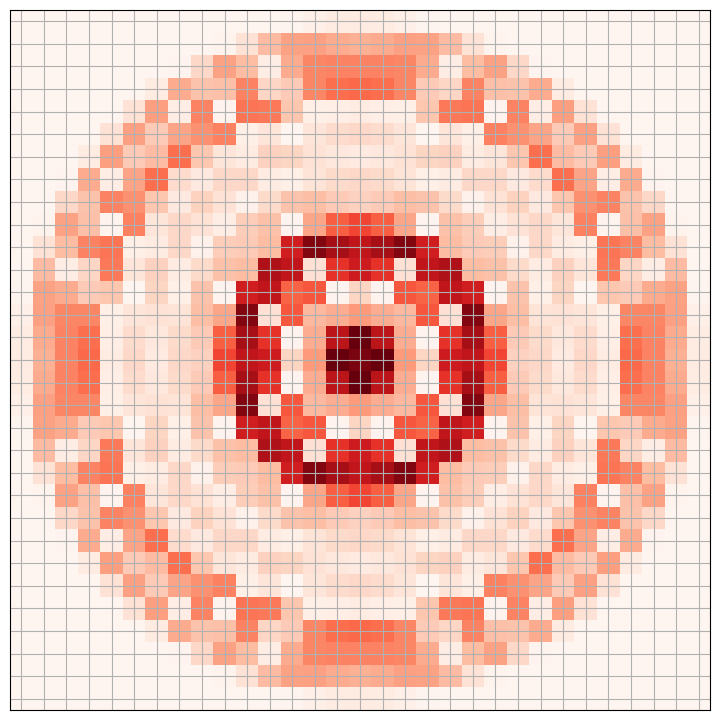

In [27]:
import matplotlib.ticker as plticker
n_filter = filters.shape[0]
n_chan = filters.shape[1]
fig = plt.figure(constrained_layout=False, figsize=(20, 20))
outergrid = fig.add_gridspec(n_chan, n_filter, left=0.05, right=0.55, wspace=0.05)
#== Plotting code ==#
# Make sure that all filters are plotted on the same colorscale
vmin = filters.min()
vmax = filters.max()
chan_cmaps = ['Reds', 'Blues']
#chan_cmaps = ['Blues', 'Reds']
#chan_labels = ['zs10', 'zs16']
for n in range(n_filter):
    filtgrid = outergrid[0, n].subgridspec(2, 1, wspace=0.1)
    for chan in range(n_chan):
        ax = fig.add_subplot(filtgrid[chan, 0])
        #if chan == 0:
        #    ax.set_title("Filter " + str(n))
        myInterval=1
        loc = plticker.MultipleLocator(base=myInterval)
        ax.xaxis.set_major_locator(loc)
        ax.yaxis.set_major_locator(loc)
        # Add the grid
        ax.grid(which='major', axis='both', linestyle='-')
        ax.imshow(filters[n, chan], cmap=chan_cmaps[chan], vmin=vmin, vmax=vmax, norm='linear')
        #ax.imshow(filters[n, chan], vmin=vmin, vmax=vmax)
        ax.tick_params(
            bottom=False,
            labelbottom=False,
            left=False,
            labelleft=False,
        )
        #cbar = plt.colorbar()
        #tick_font_size = 12
        #cbar.ax.tick_params(labelsize=tick_font_size)
        #ax.set_ylabel(chan_labels[chan], rotation=90, fontsize=30)
#cbar_ax = fig.add_axes([0.85, 0.3, 0.05, 0.4])
#axes[0].grid(which='minor', color='w', linestyle='-', linewidth=2)
plt.show()
#plt.savefig('paper_plot/grf_lognormal_filter_analysis.pdf', format='pdf', dpi=300, bbox_inches='tight')